# DDS-8555 Assignment 5 — Build and Evaluate Classification Models

## Part 1 — Conceptual Question 1 (ISLP p. 193)

**Show that (4.2) is equivalent to (4.3).

Max |log(p/(1-p)) - (b0 + b1*x)|: 2.6645352591003757e-15


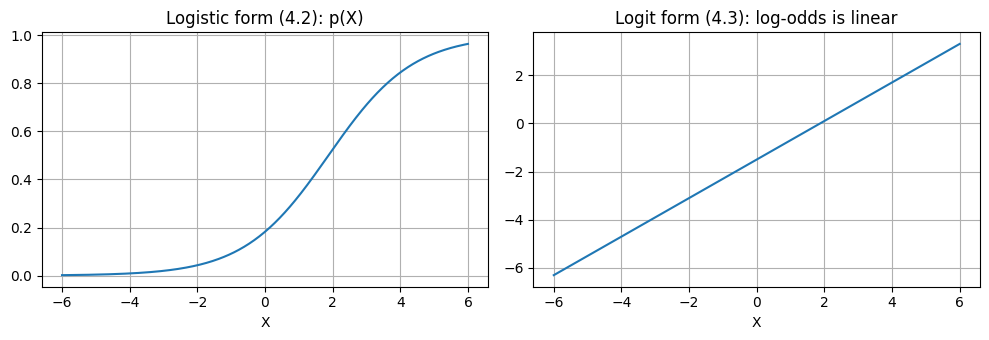

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

b0, b1 = -1.5, 0.8
x = np.linspace(-6, 6, 400)
p = np.exp(b0 + b1*x) / (1 + np.exp(b0 + b1*x))                      # (4.2)
print('Max |log(p/(1-p)) - (b0 + b1*x)|:', np.abs(np.log(p/(1-p)) - (b0 + b1*x)).max())   # (4.3)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(x, p); ax[0].set_title('Logistic form (4.2): p(X)'); ax[0].set_xlabel('X'); ax[0].grid()
ax[1].plot(x, np.log(p/(1-p))); ax[1].set_title('Logit form (4.3): log-odds is linear'); ax[1].set_xlabel('X'); ax[1].grid()
plt.tight_layout(); plt.show()

## Part 2 — Applied Question 13 (ISLP pp. 196–197)
### (a) Numerical and graphical summaries

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
(1089, 10)


,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Up
count,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000,1089.000
mean,2000.049,0.151,0.151,0.147,0.146,0.140,1.575,0.150,0.556
std,6.033,2.357,2.357,2.361,2.360,2.361,1.687,2.357,0.497
min,1990.000,-18.195,-18.195,-18.195,-18.195,-18.195,0.087,-18.195,0.000
25%,1995.000,-1.154,-1.154,-1.158,-1.158,-1.166,0.332,-1.154,0.000
50%,2000.000,0.241,0.241,0.241,0.238,0.234,1.003,0.241,1.000
75%,2005.000,1.405,1.409,1.409,1.409,1.405,2.054,1.405,1.000
max,2010.000,12.026,12.026,12.026,12.026,12.026,9.328,12.026,1.000


Direction
Up      0.556
Down    0.444
Name: proportion, dtype: float64


,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Up
Year,1.000,-0.032,-0.033,-0.030,-0.031,-0.031,0.842,-0.032,-0.022
Lag1,-0.032,1.000,-0.075,0.059,-0.071,-0.008,-0.065,-0.075,-0.050
Lag2,-0.033,-0.075,1.000,-0.076,0.058,-0.072,-0.086,0.059,0.073
Lag3,-0.030,0.059,-0.076,1.000,-0.075,0.061,-0.069,-0.071,-0.023
Lag4,-0.031,-0.071,0.058,-0.075,1.000,-0.076,-0.061,-0.008,-0.021
Lag5,-0.031,-0.008,-0.072,0.061,-0.076,1.000,-0.059,0.011,-0.018
Volume,0.842,-0.065,-0.086,-0.069,-0.061,-0.059,1.000,-0.033,-0.018
Today,-0.032,-0.075,0.059,-0.071,-0.008,0.011,-0.033,1.000,0.720
Up,-0.022,-0.050,0.073,-0.023,-0.021,-0.018,-0.018,0.720,1.000


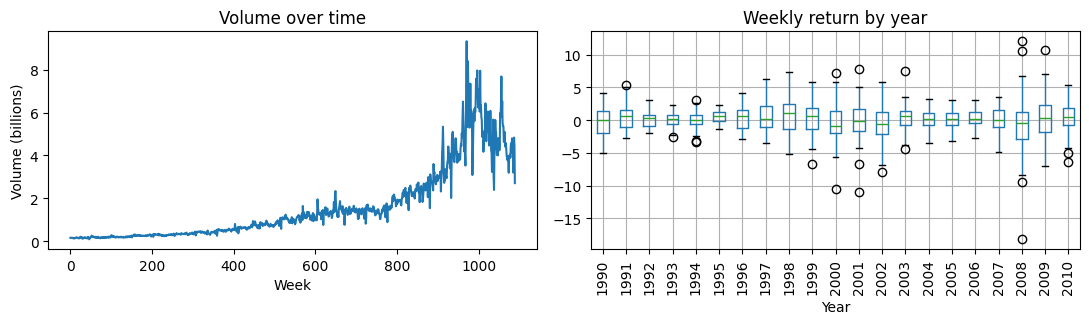

In [2]:
!pip install -q ISLP
from ISLP import load_data
import statsmodels.api as sm
import matplotlib.pyplot as plt

weekly = load_data('Weekly')
weekly['Up'] = (weekly['Direction'] == 'Up').astype(int)
print(weekly.shape)
display(weekly.describe().round(3))
print(weekly['Direction'].value_counts(normalize=True).round(3))
display(weekly.drop(columns='Direction').corr().round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(weekly.index, weekly['Volume']); ax[0].set_title('Volume over time'); ax[0].set_xlabel('Week'); ax[0].set_ylabel('Volume (billions)')
weekly.boxplot(column='Today', by='Year', ax=ax[1], rot=90); ax[1].set_title('Weekly return by year'); plt.suptitle('')
plt.tight_layout(); plt.show()

**Finding:** The only strong relationship is **Year and Volume** (r = .842); trading volume grew steadily from 1990 to 2010. The lag variables are almost uncorrelated with each other and with Today (|r| < .08), as weak-form market efficiency predicts. Returns were most volatile in 2000–2002 and 2008. The market went Up in 55.6% of weeks, so a model has to beat 55.6% to be better than always guessing "Up".

### (b) Logistic regression: Direction ~ Lag1–Lag5 + Volume

In [3]:
X_full = sm.add_constant(weekly[['Lag1','Lag2','Lag3','Lag4','Lag5','Volume']])
glm_full = sm.GLM(weekly['Up'], X_full, family=sm.families.Binomial()).fit()
print(glm_full.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                     Up   No. Observations:                 1089
Model:                            GLM   Df Residuals:                     1082
Model Family:                Binomial   Df Model:                            6
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -743.18
Date:                Fri, 20 Nov 2026   Deviance:                       1486.4
Time:                        20:14:01   Pearson chi2:                 1.09e+03
No. Iterations:                     4   Pseudo R-squ. (CS):           0.009000
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2669      0.086      3.106      0.0

**Finding:** Only **Lag2** is significant at the 5% level (b = 0.058, p = .030). A positive return two weeks ago is linked to slightly higher odds of an Up week (odds ratio $e^{0.058}$ = 1.06 per 1% return). Lag1 (p = .118) and the other predictors are not significant. With six tests, one p-value near .03 could be chance.

### (c) Confusion matrix and overall fraction correct

In [4]:
def confusion(truth, pred):
    return pd.crosstab(pd.Series(pred, name='Predicted'), pd.Series(truth, name='Truth')).reindex(
        index=['Down','Up'], columns=['Down','Up'], fill_value=0)

pred_full = np.where(glm_full.predict(X_full) > .5, 'Up', 'Down')
cm = confusion(weekly['Direction'], pred_full); display(cm)
print('Fraction correct:', round((pred_full == weekly['Direction']).mean(), 4))
print('Sensitivity (Up weeks caught):', round(cm.loc['Up','Up'] / cm['Up'].sum(), 3))
print('Specificity (Down weeks caught):', round(cm.loc['Down','Down'] / cm['Down'].sum(), 3))

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


Fraction correct: 0.5611
Sensitivity (Up weeks caught): 0.921
Specificity (Down weeks caught): 0.112


**Finding:** The model is right 56.1% of the time on the training data, barely above the 55.6% base rate. It predicts Up in 987 of 1,089 weeks. That catches 92.1% of Up weeks but only 11.2% of Down weeks (54 of 484). Most of its mistakes are **false positives**: 430 Down weeks called Up. This is training accuracy, so it is optimistic.

### (d)–(h) Train 1990–2008, test 2009–2010, Lag2 only

In [5]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

train_wk = weekly['Year'] <= 2008
Xw_train, Xw_test = weekly.loc[train_wk, ['Lag2']], weekly.loc[~train_wk, ['Lag2']]
yw_train, yw_test = weekly.loc[train_wk, 'Direction'], weekly.loc[~train_wk, 'Direction']
print('Train:', len(yw_train), 'Test:', len(yw_test), 'Test share Up:', round((yw_test == 'Up').mean(), 4))

glm_lag2 = sm.GLM((yw_train == 'Up').astype(int), sm.add_constant(Xw_train), family=sm.families.Binomial()).fit()
preds_13 = {
    '(d) Logistic': np.where(glm_lag2.predict(sm.add_constant(Xw_test)) > .5, 'Up', 'Down'),
    '(e) LDA': LinearDiscriminantAnalysis().fit(Xw_train, yw_train).predict(Xw_test),
    '(f) QDA': QuadraticDiscriminantAnalysis().fit(Xw_train, yw_train).predict(Xw_test),
    '(g) KNN, K=1': KNeighborsClassifier(n_neighbors=1).fit(Xw_train, yw_train).predict(Xw_test),
    '(h) Naive Bayes': GaussianNB().fit(Xw_train, yw_train).predict(Xw_test),
}
for name, pred in preds_13.items():
    print(f'\n{name}: fraction correct = {(pred == yw_test.values).mean():.4f}')
    display(confusion(yw_test.values, pred))

Train: 985 Test: 104 Test share Up: 0.5865

(d) Logistic: fraction correct = 0.6250


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56



(e) LDA: fraction correct = 0.6250


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56



(f) QDA: fraction correct = 0.5865


Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61



(g) KNN, K=1: fraction correct = 0.4904


Truth,Down,Up
Predicted,,
Down,22,32
Up,21,29



(h) Naive Bayes: fraction correct = 0.5865


Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


### (i) Which method is best?

In [6]:
results_13 = pd.DataFrame({'Method': list(preds_13),
                           'Test accuracy': [(p == yw_test.values).mean() for p in preds_13.values()]})
results_13.loc[len(results_13)] = ['Baseline: always Up', (yw_test == 'Up').mean()]
display(results_13.sort_values('Test accuracy', ascending=False).round(4))

,Method,Test accuracy
0,(d) Logistic,0.6250
1,(e) LDA,0.6250
2,(f) QDA,0.5865
4,(h) Naive Bayes,0.5865
5,Baseline: always Up,0.5865
3,"(g) KNN, K=1",0.4904


**Finding:** **Logistic regression and LDA tie for best at 62.5%** (65 of 104 weeks), 3.8 points above the 58.7% base rate. With one predictor and two classes they give the same linear rule, so their confusion matrices are identical. **QDA and naive Bayes predict Up for every week** (58.7%). Their boundary never falls inside the observed range of Lag2, and with one predictor Gaussian naive Bayes is effectively QDA. **KNN with K = 1** overfits noise and gets 49.0%, worse than a coin flip. Logistic regression or LDA is the best choice. Still, 104 test weeks is a small sample, so the gain is weak evidence that returns are predictable.

### (j) Experiment with predictors, transformations, interactions and K

Family,KNN,LDA,Logistic,Naive Bayes,QDA
Predictors,,,,,
Lag1 + Lag2,0.6250,0.5769,0.5769,0.5385,0.5577
Lag1 + Lag2 + Lag1:Lag2,0.5962,0.5769,0.5769,0.4712,0.4615
Lag1-Lag5 + Volume,0.6250,0.4615,0.4615,0.4519,0.4327
Lag2,0.6154,0.6250,0.6250,0.5865,0.5865
Lag2 + Lag2^2,0.6058,0.6154,0.6250,0.5769,0.6250
Lag2 + log(Volume),0.5865,0.5769,0.5769,0.5481,0.5577


Best K for each predictor set:


,Predictors,Method,Test accuracy,Family
70,Lag1 + Lag2,KNN K=25,0.6250,KNN
315,Lag1-Lag5 + Volume,KNN K=83,0.6250,KNN
27,Lag2,KNN K=47,0.6154,KNN
195,Lag2 + Lag2^2,KNN K=59,0.6058,KNN
140,Lag1 + Lag2 + Lag1:Lag2,KNN K=57,0.5962,KNN
254,Lag2 + log(Volume),KNN K=69,0.5865,KNN


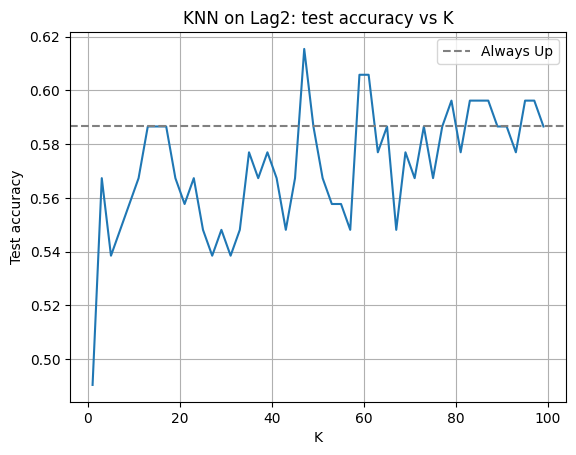

Best combination: Logistic regression, Lag2 only


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

wk = weekly.copy()
wk['Lag1xLag2'] = wk['Lag1'] * wk['Lag2']
wk['Lag2_sq'] = wk['Lag2'] ** 2
wk['log_Volume'] = np.log(wk['Volume'])
predictor_sets = {
    'Lag2': ['Lag2'],
    'Lag1 + Lag2': ['Lag1','Lag2'],
    'Lag1 + Lag2 + Lag1:Lag2': ['Lag1','Lag2','Lag1xLag2'],
    'Lag2 + Lag2^2': ['Lag2','Lag2_sq'],
    'Lag2 + log(Volume)': ['Lag2','log_Volume'],
    'Lag1-Lag5 + Volume': ['Lag1','Lag2','Lag3','Lag4','Lag5','Volume'],
}
methods = {'Logistic': lambda: LogisticRegression(C=1e6), 'LDA': LinearDiscriminantAnalysis,
           'QDA': QuadraticDiscriminantAnalysis, 'Naive Bayes': GaussianNB}
rows = []
for set_name, cols in predictor_sets.items():
    Xa, Xb = wk.loc[train_wk, cols], wk.loc[~train_wk, cols]
    for m_name, make in methods.items():
        rows.append([set_name, m_name, accuracy_score(yw_test, make().fit(Xa, yw_train).predict(Xb))])
    for k in range(1, 101, 2):
        knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(Xa, yw_train)
        rows.append([set_name, f'KNN K={k}', accuracy_score(yw_test, knn.predict(Xb))])
exp = pd.DataFrame(rows, columns=['Predictors','Method','Test accuracy'])
exp['Family'] = exp['Method'].str.split(' K=').str[0]
display(exp.pivot_table(index='Predictors', columns='Family', values='Test accuracy', aggfunc='max').round(4))
print('Best K for each predictor set:')
display(exp[exp.Family == 'KNN'].sort_values('Test accuracy', ascending=False).groupby('Predictors').head(1).round(4))

knn_curve = exp[(exp.Predictors == 'Lag2') & (exp.Family == 'KNN')]
plt.plot(knn_curve['Method'].str.split('=').str[1].astype(int), knn_curve['Test accuracy'])
plt.axhline((yw_test == 'Up').mean(), color='gray', linestyle='--', label='Always Up')
plt.xlabel('K'); plt.ylabel('Test accuracy'); plt.title('KNN on Lag2: test accuracy vs K'); plt.legend(); plt.grid(); plt.show()

print('Best combination: Logistic regression, Lag2 only')
display(confusion(yw_test.values, preds_13['(d) Logistic']))

**Finding:** No transformation or interaction beat **Lag2 alone with logistic regression or LDA (62.5%)**. Adding Lag2² left logistic regression at 62.5%, and it lifted QDA to 62.5%. Adding all five lags plus Volume cut accuracy to about 46%, a clear sign of overfitting noise. KNN improves a lot once K grows past 1. It reaches 61.5% on Lag2 and up to 62.5% with some other predictor sets. Its accuracy swings with K, though, and choosing K by its test score overstates how well it would do on new data. The best combination is **logistic regression (or LDA) with Lag2 only**. Its confusion matrix is shown above: 9 Down and 56 Up weeks correct, 34 false positives and 5 false negatives. It is the simplest model and is as accurate as anything else tried.

## Part 3 — Kaggle: Multi-class Prediction of Obesity Risk



**Assumptions to discuss:** independent observations; linear log-odds for logistic regression; approximate normality and equal class covariance for LDA; conditional independence for Naïve Bayes; and the effect of scaling and kernel selection for SVM. These assumptions are not automatically established by model accuracy.


In [8]:
# 1. Libraries and dataset loading (Google Colab or local Jupyter)
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Put train.csv and test.csv in the notebook's working directory.
# In Colab, run this cell and choose both files if they are not already present.
if not (Path("train.csv").exists() and Path("test.csv").exists()):
    try:
        from google.colab import files
        print("Upload Kaggle train.csv and test.csv")
        files.upload()
    except ImportError:
        print("Place train.csv and test.csv beside the notebook, then rerun.")

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
TARGET = "NObeyesdad"
assert TARGET in train.columns and TARGET not in test.columns
assert "id" in train.columns and "id" in test.columns
print("Train:", train.shape, "Test:", test.shape)
print("Classes:", train[TARGET].value_counts().to_dict())


Upload Kaggle train.csv and test.csv


Saving test.csv to test.csv
Saving train.csv to train.csv
Train: (20758, 18) Test: (13840, 17)
Classes: {'Obesity_Type_III': 4046, 'Obesity_Type_II': 3248, 'Normal_Weight': 3082, 'Obesity_Type_I': 2910, 'Insufficient_Weight': 2523, 'Overweight_Level_II': 2522, 'Overweight_Level_I': 2427}


In [9]:
# 2. Features and preprocessing
# BMI is derived from Height and Weight; omit Height and Weight to reduce redundancy.
def add_bmi(df):
    result = df.copy()
    result["BMI"] = result["Weight"] / result["Height"].replace(0, np.nan).pow(2)
    return result.drop(columns=["Height", "Weight"])

X = add_bmi(train.drop(columns=[TARGET, "id"]))
y = train[TARGET]
X_kaggle = add_bmi(test.drop(columns=["id"]))
numeric = X.select_dtypes(include=np.number).columns.tolist()
categorical = X.select_dtypes(exclude=np.number).columns.tolist()

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical)
])
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print("Training:", len(X_train), "Validation:", len(X_val))
print("Majority-class baseline:", round(y_val.value_counts(normalize=True).max(), 4))


Training: 16606 Validation: 4152
Majority-class baseline: 0.1948


In [10]:
# 3. Train the four required models (n_jobs is not used)
# LogisticRegression uses L2 regularization by default; C=1.0.
models = {
    "Logistic_Regression": LogisticRegression(max_iter=1500, solver="lbfgs", C=1.0),
    "LDA": LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    "Naive_Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", C=3.0, gamma="scale")
}
fitted = {}
scores = []
for name, classifier in models.items():
    pipeline = Pipeline([("preprocess", preprocess), ("model", classifier)])
    print("Training:", name)
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_val)
    fitted[name] = pipeline
    scores.append({"Model": name, "Validation accuracy": accuracy_score(y_val, predictions)})
    print(classification_report(y_val, predictions, zero_division=0))
results = pd.DataFrame(scores).sort_values("Validation accuracy", ascending=False)
display(results)


Training: Logistic_Regression
                     precision    recall  f1-score   support

Insufficient_Weight       0.89      0.95      0.91       505
      Normal_Weight       0.86      0.81      0.83       617
     Obesity_Type_I       0.81      0.80      0.80       582
    Obesity_Type_II       0.90      0.95      0.93       650
   Obesity_Type_III       0.99      1.00      1.00       809
 Overweight_Level_I       0.74      0.70      0.72       485
Overweight_Level_II       0.72      0.71      0.72       504

           accuracy                           0.86      4152
          macro avg       0.84      0.84      0.84      4152
       weighted avg       0.86      0.86      0.86      4152

Training: LDA
                     precision    recall  f1-score   support

Insufficient_Weight       0.84      0.96      0.90       505
      Normal_Weight       0.85      0.73      0.78       617
     Obesity_Type_I       0.78      0.77      0.78       582
    Obesity_Type_II       0.89      0

,Model,Validation accuracy
3,SVM,0.871869
0,Logistic_Regression,0.858382
1,LDA,0.830925
2,Naive_Bayes,0.636079


In [11]:
# 4. Compare model errors
best_name = results.iloc[0]["Model"]
best_predictions = fitted[best_name].predict(X_val)
print("Best validation model:", best_name)
print("Confusion matrix (rows = actual classes):")
display(pd.DataFrame(
    confusion_matrix(y_val, best_predictions, labels=sorted(y.unique())),
    index=sorted(y.unique()), columns=sorted(y.unique())
))
print("Important: a single validation split estimates performance; it does not prove assumptions.")


Best validation model: SVM
Confusion matrix (rows = actual classes):


,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Insufficient_Weight,479,25,0,0,0,1,0
Normal_Weight,46,510,1,0,0,49,11
Obesity_Type_I,1,0,486,32,3,23,37
Obesity_Type_II,0,0,23,624,0,0,3
Obesity_Type_III,0,0,0,1,807,0,1
Overweight_Level_I,2,49,19,0,0,341,74
Overweight_Level_II,0,8,53,10,0,60,373


Important: a single validation split estimates performance; it does not prove assumptions.


In [12]:
# 5. Fit each model on all labeled data and create four Kaggle CSV files
output_dir = Path("Assignment5_submissions")
output_dir.mkdir(exist_ok=True)
for name, pipeline in fitted.items():
    pipeline.fit(X, y)
    submission = pd.DataFrame({
        "id": test["id"],
        TARGET: pipeline.predict(X_kaggle)
    })
    assert len(submission) == len(test)
    assert submission[TARGET].isin(y.unique()).all()
    file_path = output_dir / f"{name}.csv"
    submission.to_csv(file_path, index=False)
    print("Created:", file_path)

# In Colab, download all files as a ZIP.
import zipfile
with zipfile.ZipFile("Assignment5_submissions.zip", "w") as archive:
    for csv_path in output_dir.glob("*.csv"):
        archive.write(csv_path, arcname=csv_path.name)
print("Created Assignment5_submissions.zip")
try:
    from google.colab import files
    files.download("Assignment5_submissions.zip")
except ImportError:
    pass


Created: Assignment5_submissions/Logistic_Regression.csv
Created: Assignment5_submissions/LDA.csv
Created: Assignment5_submissions/Naive_Bayes.csv
Created: Assignment5_submissions/SVM.csv
Created Assignment5_submissions.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>